### 4.1.1. Raw dataset (Not resampled)

In [1]:
import pandas as pd
from datetime import datetime
import numpy as np

In [2]:
EU_countries=['AUSTRIA','BELGIUM','BULGARIA',
        'CROATIA','CZECH_REPUBLIC', 'ESTONIA',
        'FINLAND','FRANCE', 'GERMANY',
        'GREECE','HUNGARY','LATVIA','LITHUANIA',
        'NETHERLANDS', 'POLAND','PORTUGAL',
        'ROMANIA', 'SLOVAKIA', 'SLOVENIA', 'SPAIN']

energy_types_keep=["MTU (UTC)","Sequence","Day-ahead Price (EUR/MWh)"]

energy_prices_eu_dfs=[]
for current_country in EU_countries:
    #Load electricity total load time series:
    energy_prices_df=pd.concat([pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2023.csv',sep=','),
                            pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2024.csv',sep=','),
                            pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2025.csv',sep=',')],axis=0)

    #Format columns and
    #Select a set of time series for the current country:
    energy_prices_df=energy_prices_df[energy_types_keep]
    energy_prices_df.columns=['MTU', 'Sequence', current_country[0]+str.lower(current_country[1:])+' Day-ahead Price (EUR/MWh)']
    
    energy_prices_df=energy_prices_df.loc[(energy_prices_df['Sequence'] == 'Sequence 1') | 
                                            (energy_prices_df['Sequence'] == 'Without Sequence')]
    energy_prices_df=energy_prices_df.drop(["Sequence"],axis=1)
    
    current_dates=energy_prices_df[["MTU"]]
    energy_prices_df=energy_prices_df.drop(["MTU"],axis=1)
    
    #Change format of dates:
    current_dates=current_dates["MTU"].str.replace(" (UTC)","",regex=False)
    current_dates=[datetime.strptime(date.split(" - ")[-1],'%d/%m/%Y %H:%M:%S') for date in current_dates.values]
    energy_prices_df.index=np.array(current_dates)

    energy_prices_eu_dfs.append(energy_prices_df)

#Concat Eu dataframes as well as drop  missing values: 
energy_prices_eu_frame=pd.concat(energy_prices_eu_dfs,axis=1).dropna()

#Convert columns to dtype float32: 
for col in energy_prices_eu_frame.columns:
    energy_prices_eu_frame[col]=energy_prices_eu_frame[col].astype(np.float32)
# energy_prices_eu_frame=energy_prices_eu_frame.resample('h').mean()
energy_prices_eu_frame=energy_prices_eu_frame


#Set the start of the train dataset:
datetime_indices=pd.DatetimeIndex(['2023-01-01 00:00:00'])
energy_prices_eu_frame=energy_prices_eu_frame[(energy_prices_eu_frame.index >= datetime_indices[0])]

In [3]:
energy_prices_eu_frame.describe().loc[['mean', 'std', 'min', 'max', 'count']]

,Austria Day-ahead Price (EUR/MWh),Belgium Day-ahead Price (EUR/MWh),Bulgaria Day-ahead Price (EUR/MWh),Croatia Day-ahead Price (EUR/MWh),Czech_republic Day-ahead Price (EUR/MWh),Estonia Day-ahead Price (EUR/MWh),Finland Day-ahead Price (EUR/MWh),France Day-ahead Price (EUR/MWh),Germany Day-ahead Price (EUR/MWh),Greece Day-ahead Price (EUR/MWh),Hungary Day-ahead Price (EUR/MWh),Latvia Day-ahead Price (EUR/MWh),Lithuania Day-ahead Price (EUR/MWh),Netherlands Day-ahead Price (EUR/MWh),Poland Day-ahead Price (EUR/MWh),Portugal Day-ahead Price (EUR/MWh),Romania Day-ahead Price (EUR/MWh),Slovakia Day-ahead Price (EUR/MWh),Slovenia Day-ahead Price (EUR/MWh),Spain Day-ahead Price (EUR/MWh)
mean,96.569885,82.979065,105.663498,103.301117,95.535629,83.280724,44.000633,66.529236,88.495575,105.724762,106.943665,87.383728,87.177887,86.724998,104.181969,69.409180,106.650581,101.394875,102.359558,68.546173
std,49.589294,47.414944,62.668701,54.988121,49.891434,72.735977,57.949650,47.492764,51.966080,58.366753,63.006702,70.902840,71.118416,50.126675,49.426838,46.135433,63.050865,55.044155,53.587486,47.163330
min,-500.000000,-462.329987,-100.629997,-500.000000,-224.490005,-60.040001,-500.000000,-134.940002,-500.000000,-50.000000,-500.000000,-56.549999,-56.549999,-500.000000,-132.949997,-5.000000,-106.360001,-202.699997,-500.000000,-15.000000
max,850.000000,565.460022,950.010010,902.219971,844.630005,1896.000000,1896.000000,473.279999,936.280029,942.000000,999.010010,1478.910034,1478.910034,872.960022,630.190002,240.000000,1021.609985,850.000000,1022.270020,240.000000
count,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000


In [4]:
stats = energy_prices_eu_frame.agg(['mean', 'std', 'min', 'max']).T.round(2)

latex_table = stats.to_latex(
    caption="Summary statistics of day-ahead electricity prices (EUR/MWh)",
    label="tab:price_stats",
    float_format="%.2f"
)

print(latex_table)

\begin{table}
\caption{Summary statistics of day-ahead electricity prices (EUR/MWh)}
\label{tab:price_stats}
\begin{tabular}{lrrrr}
\toprule
 & mean & std & min & max \\
\midrule
Austria Day-ahead Price (EUR/MWh) & 96.57 & 49.59 & -500.00 & 850.00 \\
Belgium Day-ahead Price (EUR/MWh) & 82.98 & 47.41 & -462.33 & 565.46 \\
Bulgaria Day-ahead Price (EUR/MWh) & 105.66 & 62.67 & -100.63 & 950.01 \\
Croatia Day-ahead Price (EUR/MWh) & 103.30 & 54.99 & -500.00 & 902.22 \\
Czech_republic Day-ahead Price (EUR/MWh) & 95.54 & 49.89 & -224.49 & 844.63 \\
Estonia Day-ahead Price (EUR/MWh) & 83.28 & 72.74 & -60.04 & 1896.00 \\
Finland Day-ahead Price (EUR/MWh) & 44.00 & 57.95 & -500.00 & 1896.00 \\
France Day-ahead Price (EUR/MWh) & 66.53 & 47.49 & -134.94 & 473.28 \\
Germany Day-ahead Price (EUR/MWh) & 88.50 & 51.97 & -500.00 & 936.28 \\
Greece Day-ahead Price (EUR/MWh) & 105.72 & 58.37 & -50.00 & 942.00 \\
Hungary Day-ahead Price (EUR/MWh) & 106.94 & 63.01 & -500.00 & 999.01 \\
Latvia Day-ahead Pr

\begin{table} 
\caption{Summary statistics of day-ahead electricity prices (EUR/MWh)} 
\label{tab:price_stats} 
\begin{tabular}{lrrrr} 
\toprule
& mean & std & min & max \\ 
\midrule 
Austria & 96.57 & 49.59 & -500.00 & 850.00 \\ 
Belgium & 82.98 & 47.41 & -462.33 & 565.46 \\ 
Bulgaria & 105.66 & 62.67 & -100.63 & 950.01 \\ 
Croatia & 103.30 & 54.99 & -500.00 & 902.22 \\ 
Czech Republic & 95.54 & 49.89 & -224.49 & 844.63 \\ 
Estonia & 83.28 & 72.74 & -60.04 & 1896.00 \\ 
Finland & 44.00 & 57.95 & -500.00 & 1896.00 \\ 
France & 66.53 & 47.49 & -134.94 & 473.28 \\ 
Germany & 88.50 & 51.97 & -500.00 & 936.28 \\ 
Greece & 105.72 & 58.37 & -50.00 & 942.00 \\ 
Hungary & 106.94 & 63.01 & -500.00 & 999.01 \\ 
Latvia & 87.38 & 70.90 & -56.55 & 1478.91 \\ 
Lithuania & 87.18 & 71.12 & -56.55 & 1478.91 \\ 
Netherlands & 86.72 & 50.13 & -500.00 & 872.96 \\ 
Poland & 104.18 & 49.43 & -132.95 & 630.19 \\ 
Portugal & 69.41 & 46.14 & -5.00 & 240.00 \\ 
Romania & 106.65 & 63.05 & -106.36 & 1021.61 \\ 
Slovakia & 101.39 & 55.04 & -202.70 & 850.00 \\ 
Slovenia & 102.36 & 53.59 & -500.00 & 1022.27 \\ 
Spain & 68.55 & 47.16 & -15.00 & 240.00 \\ 
\bottomrule 
\end{tabular} 
\end{table}

| Region         | mean   | std   | min     | max     |
| -------------- | ------ | ----- | ------- | ------- |
| Austria        | 96.57  | 49.59 | -500.00 | 850.00  |
| Belgium        | 82.98  | 47.41 | -462.33 | 565.46  |
| Bulgaria       | 105.66 | 62.67 | -100.63 | 950.01  |
| Croatia        | 103.30 | 54.99 | -500.00 | 902.22  |
| Czech Republic | 95.54  | 49.89 | -224.49 | 844.63  |
| Estonia        | 83.28  | 72.74 | -60.04  | 1896.00 |
| Finland        | 44.00  | 57.95 | -500.00 | 1896.00 |
| France         | 66.53  | 47.49 | -134.94 | 473.28  |
| Germany        | 88.50  | 51.97 | -500.00 | 936.28  |
| Greece         | 105.72 | 58.37 | -50.00  | 942.00  |
| Hungary        | 106.94 | 63.01 | -500.00 | 999.01  |
| Latvia         | 87.38  | 70.90 | -56.55  | 1478.91 |
| Lithuania      | 87.18  | 71.12 | -56.55  | 1478.91 |
| Netherlands    | 86.72  | 50.13 | -500.00 | 872.96  |
| Poland         | 104.18 | 49.43 | -132.95 | 630.19  |
| Portugal       | 69.41  | 46.14 | -5.00   | 240.00  |
| Romania        | 106.65 | 63.05 | -106.36 | 1021.61 |
| Slovakia       | 101.39 | 55.04 | -202.70 | 850.00  |
| Slovenia       | 102.36 | 53.59 | -500.00 | 1022.27 |
| Spain          | 68.55  | 47.16 | -15.00  | 240.00  |


In [5]:
energy_prices_eu_frame.describe()

,Austria Day-ahead Price (EUR/MWh),Belgium Day-ahead Price (EUR/MWh),Bulgaria Day-ahead Price (EUR/MWh),Croatia Day-ahead Price (EUR/MWh),Czech_republic Day-ahead Price (EUR/MWh),Estonia Day-ahead Price (EUR/MWh),Finland Day-ahead Price (EUR/MWh),France Day-ahead Price (EUR/MWh),Germany Day-ahead Price (EUR/MWh),Greece Day-ahead Price (EUR/MWh),Hungary Day-ahead Price (EUR/MWh),Latvia Day-ahead Price (EUR/MWh),Lithuania Day-ahead Price (EUR/MWh),Netherlands Day-ahead Price (EUR/MWh),Poland Day-ahead Price (EUR/MWh),Portugal Day-ahead Price (EUR/MWh),Romania Day-ahead Price (EUR/MWh),Slovakia Day-ahead Price (EUR/MWh),Slovenia Day-ahead Price (EUR/MWh),Spain Day-ahead Price (EUR/MWh)
count,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000,52584.000000
mean,96.569885,82.979065,105.663498,103.301117,95.535629,83.280724,44.000633,66.529236,88.495575,105.724762,106.943665,87.383728,87.177887,86.724998,104.181969,69.409180,106.650581,101.394875,102.359558,68.546173
std,49.589294,47.414944,62.668701,54.988121,49.891434,72.735977,57.949650,47.492764,51.966080,58.366753,63.006702,70.902840,71.118416,50.126675,49.426838,46.135433,63.050865,55.044155,53.587486,47.163330
min,-500.000000,-462.329987,-100.629997,-500.000000,-224.490005,-60.040001,-500.000000,-134.940002,-500.000000,-50.000000,-500.000000,-56.549999,-56.549999,-500.000000,-132.949997,-5.000000,-106.360001,-202.699997,-500.000000,-15.000000
25%,76.980003,60.209999,78.410004,79.620003,75.010002,25.320000,4.090000,25.959999,67.977503,80.629997,80.150002,36.349998,35.720001,67.239998,85.727503,28.260000,79.510002,77.629997,79.809998,25.110001
50%,98.924999,86.370003,101.760002,101.550003,96.709999,79.459999,24.090000,68.029999,91.220001,102.379997,102.139999,82.660004,82.430000,90.000000,103.589996,74.529999,102.165001,99.905003,101.805000,74.160004
75%,121.110001,109.872501,131.000000,127.779999,120.000000,116.742498,69.150002,99.099998,113.660004,130.380005,131.419998,119.089996,119.019997,111.949997,124.190002,105.190002,131.380005,126.180000,126.360001,105.269997
max,850.000000,565.460022,950.010010,902.219971,844.630005,1896.000000,1896.000000,473.279999,936.280029,942.000000,999.010010,1478.910034,1478.910034,872.960022,630.190002,240.000000,1021.609985,850.000000,1022.270020,240.000000


### 4.1.4. Hourly Resampled dataset

In [6]:
EU_countries=['AUSTRIA','BELGIUM','BULGARIA',
        'CROATIA','CZECH_REPUBLIC', 'ESTONIA',
        'FINLAND','FRANCE', 'GERMANY',
        'GREECE','HUNGARY','LATVIA','LITHUANIA',
        'NETHERLANDS', 'POLAND','PORTUGAL',
        'ROMANIA', 'SLOVAKIA', 'SLOVENIA', 'SPAIN']

energy_types_keep=["MTU (UTC)","Sequence","Day-ahead Price (EUR/MWh)"]

energy_prices_eu_dfs=[]
for current_country in EU_countries:
    #Load electricity total load time series:
    energy_prices_df=pd.concat([pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2023.csv',sep=','),
                            pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2024.csv',sep=','),
                            pd.read_csv('../Energy_Production_Data/EU_Energy_Prices/'+current_country+'_ENERGY_PRICES_2025.csv',sep=',')],axis=0)

    #Format columns and
    #Select a set of time series for the current country:
    energy_prices_df=energy_prices_df[energy_types_keep]
    energy_prices_df.columns=['MTU', 'Sequence', current_country[0]+str.lower(current_country[1:])]
    
    energy_prices_df=energy_prices_df.loc[(energy_prices_df['Sequence'] == 'Sequence 1') | 
                                            (energy_prices_df['Sequence'] == 'Without Sequence')]
    energy_prices_df=energy_prices_df.drop(["Sequence"],axis=1)
    
    current_dates=energy_prices_df[["MTU"]]
    energy_prices_df=energy_prices_df.drop(["MTU"],axis=1)
    
    #Change format of dates:
    current_dates=current_dates["MTU"].str.replace(" (UTC)","",regex=False)
    current_dates=[datetime.strptime(date.split(" - ")[-1],'%d/%m/%Y %H:%M:%S') for date in current_dates.values]
    energy_prices_df.index=np.array(current_dates)

    energy_prices_eu_dfs.append(energy_prices_df)

#Concat Eu dataframes as well as drop  missing values: 
energy_prices_eu_frame=pd.concat(energy_prices_eu_dfs,axis=1).dropna()

#Convert columns to dtype float32: 
for col in energy_prices_eu_frame.columns:
    energy_prices_eu_frame[col]=energy_prices_eu_frame[col].astype(np.float32)
energy_prices_eu_frame=energy_prices_eu_frame.resample('h').mean()


#Set the start of the train dataset:
datetime_indices=pd.DatetimeIndex(['2023-01-01 00:00:00'])
energy_prices_eu_frame=energy_prices_eu_frame[(energy_prices_eu_frame.index >= datetime_indices[0])]

In [7]:
energy_prices_eu_frame.describe().loc[['mean', 'std', 'min', 'max', 'count']]

,Austria,Belgium,Bulgaria,Croatia,Czech_republic,Estonia,Finland,France,Germany,Greece,Hungary,Latvia,Lithuania,Netherlands,Poland,Portugal,Romania,Slovakia,Slovenia,Spain
mean,94.199310,83.379791,104.432747,101.252449,94.237747,86.156532,47.509914,71.973938,87.665154,107.849159,105.378433,89.022942,89.034195,86.633965,104.064507,72.630806,105.141670,100.096024,100.080414,71.803726
std,48.570366,46.664150,64.776764,55.493511,48.869465,70.376465,62.231392,47.522839,51.118702,58.324703,65.630806,66.588936,66.795227,49.803185,46.621864,45.317402,66.068481,54.481461,53.429180,46.187691
min,-500.000000,-459.247498,-100.619995,-500.000000,-221.024994,-60.040001,-500.000000,-134.940002,-500.000000,-50.000000,-500.000000,-56.549999,-56.549999,-500.000000,-122.852493,-5.000000,-106.360001,-202.024994,-500.000000,-15.000000
max,850.000000,565.460022,950.010010,902.219971,844.630005,1896.000000,1896.000000,424.005005,936.280029,942.000000,999.010010,1478.910034,1478.910034,872.960022,630.190002,234.095001,1021.609985,850.000000,1022.270020,234.095001
count,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000


In [8]:
stats = energy_prices_eu_frame.agg(['mean', 'std', 'min', 'max']).T.round(2)

latex_table = stats.to_latex(
    caption="Summary statistics of day-ahead electricity prices (EUR/MWh)",
    label="tab:price_stats",
    float_format="%.2f"
)

print(latex_table)

\begin{table}
\caption{Summary statistics of day-ahead electricity prices (EUR/MWh)}
\label{tab:price_stats}
\begin{tabular}{lrrrr}
\toprule
 & mean & std & min & max \\
\midrule
Austria & 94.20 & 48.57 & -500.00 & 850.00 \\
Belgium & 83.38 & 46.66 & -459.25 & 565.46 \\
Bulgaria & 104.43 & 64.78 & -100.62 & 950.01 \\
Croatia & 101.25 & 55.49 & -500.00 & 902.22 \\
Czech_republic & 94.24 & 48.87 & -221.02 & 844.63 \\
Estonia & 86.16 & 70.38 & -60.04 & 1896.00 \\
Finland & 47.51 & 62.23 & -500.00 & 1896.00 \\
France & 71.97 & 47.52 & -134.94 & 424.00 \\
Germany & 87.67 & 51.12 & -500.00 & 936.28 \\
Greece & 107.85 & 58.32 & -50.00 & 942.00 \\
Hungary & 105.38 & 65.63 & -500.00 & 999.01 \\
Latvia & 89.02 & 66.59 & -56.55 & 1478.91 \\
Lithuania & 89.03 & 66.80 & -56.55 & 1478.91 \\
Netherlands & 86.63 & 49.80 & -500.00 & 872.96 \\
Poland & 104.06 & 46.62 & -122.85 & 630.19 \\
Portugal & 72.63 & 45.32 & -5.00 & 234.10 \\
Romania & 105.14 & 66.07 & -106.36 & 1021.61 \\
Slovakia & 100.10 & 54.

### 4.1.2. Visualisations

In [9]:
energy_prices_eu_frame_daily=energy_prices_eu_frame.resample('D').mean()

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns


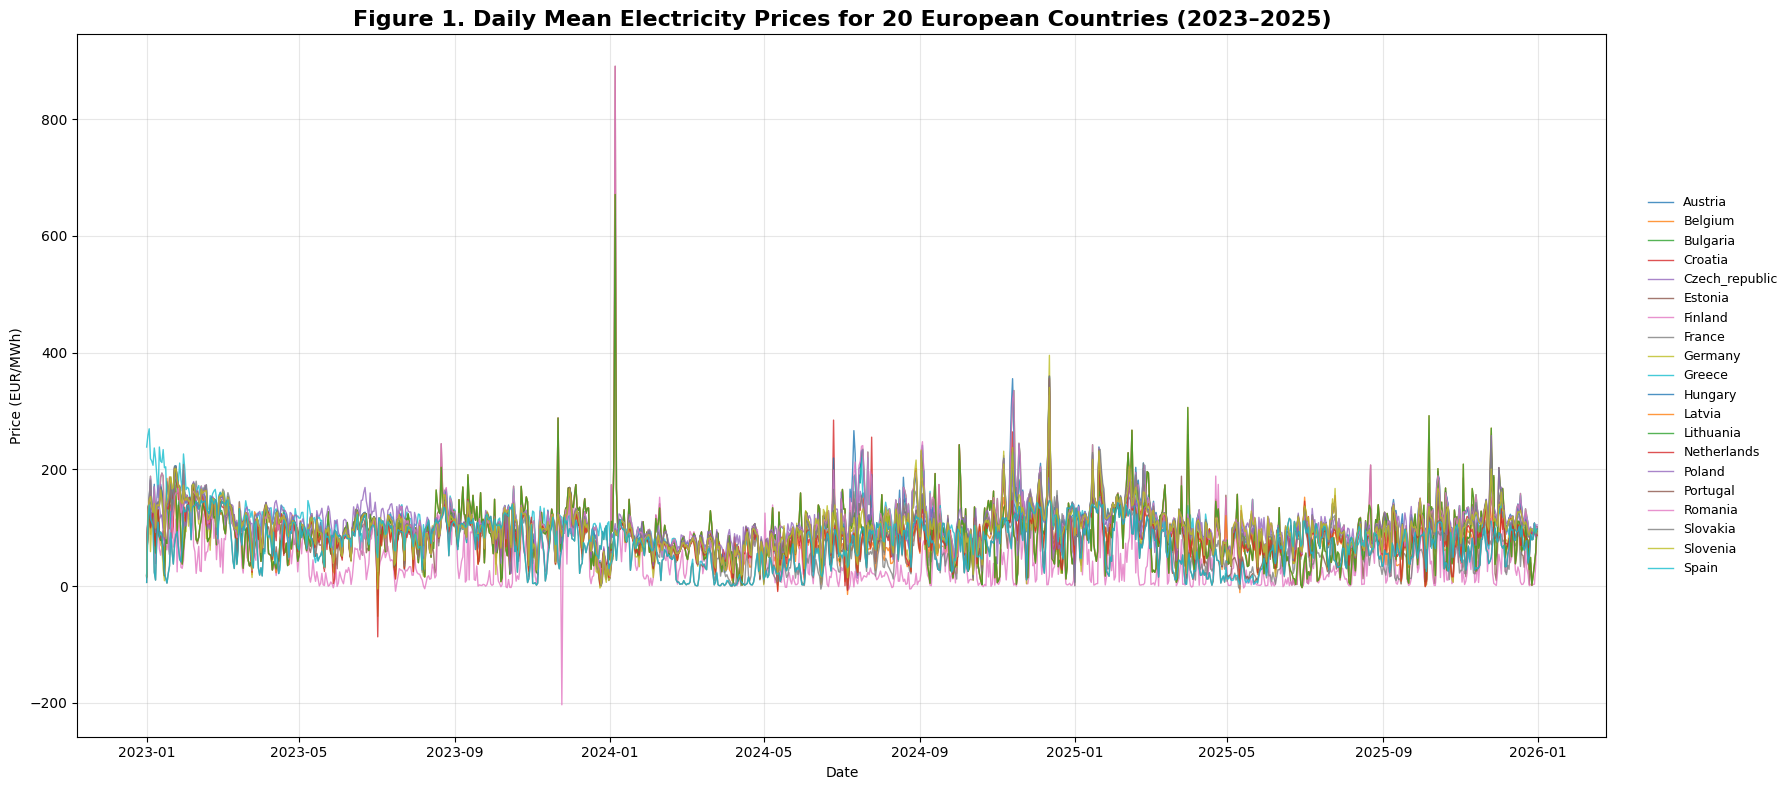

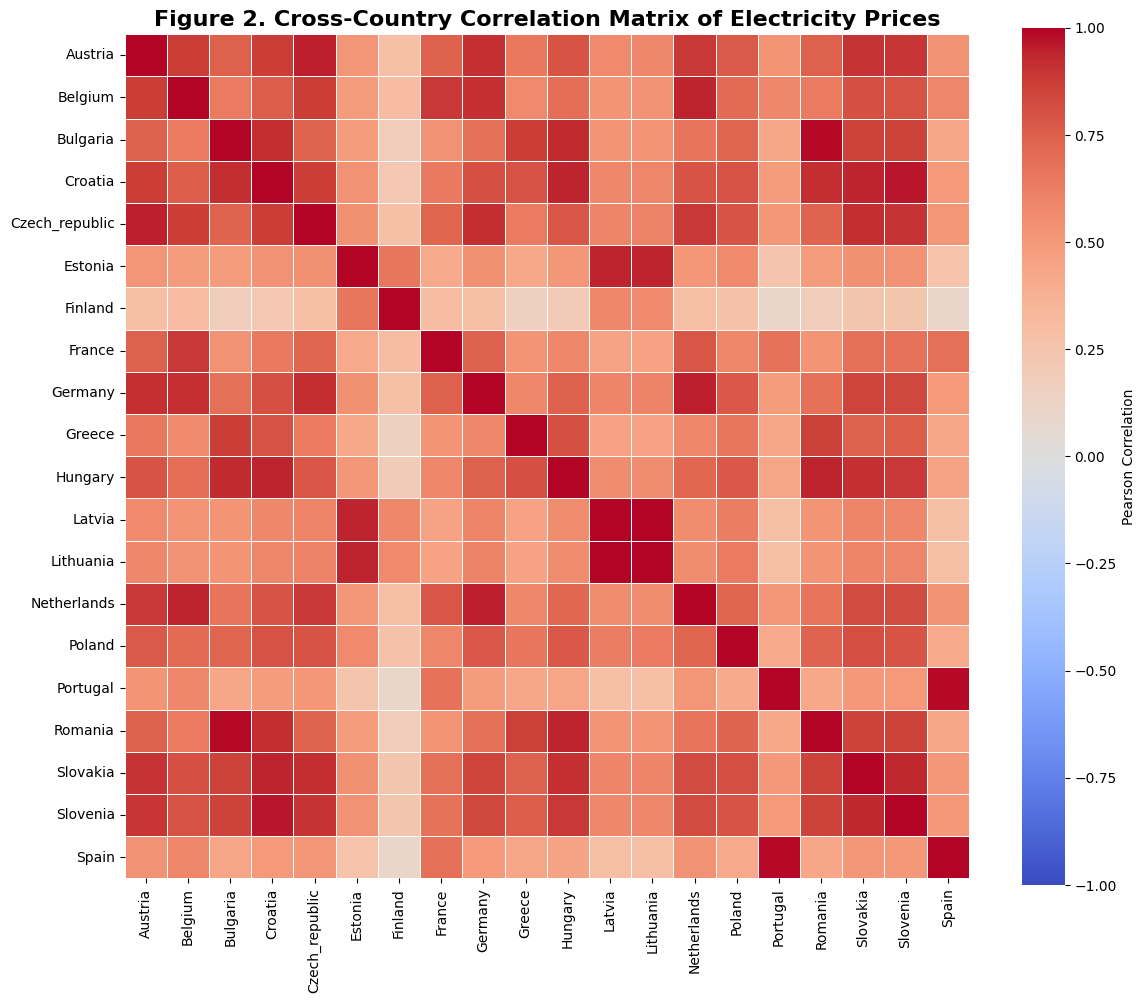

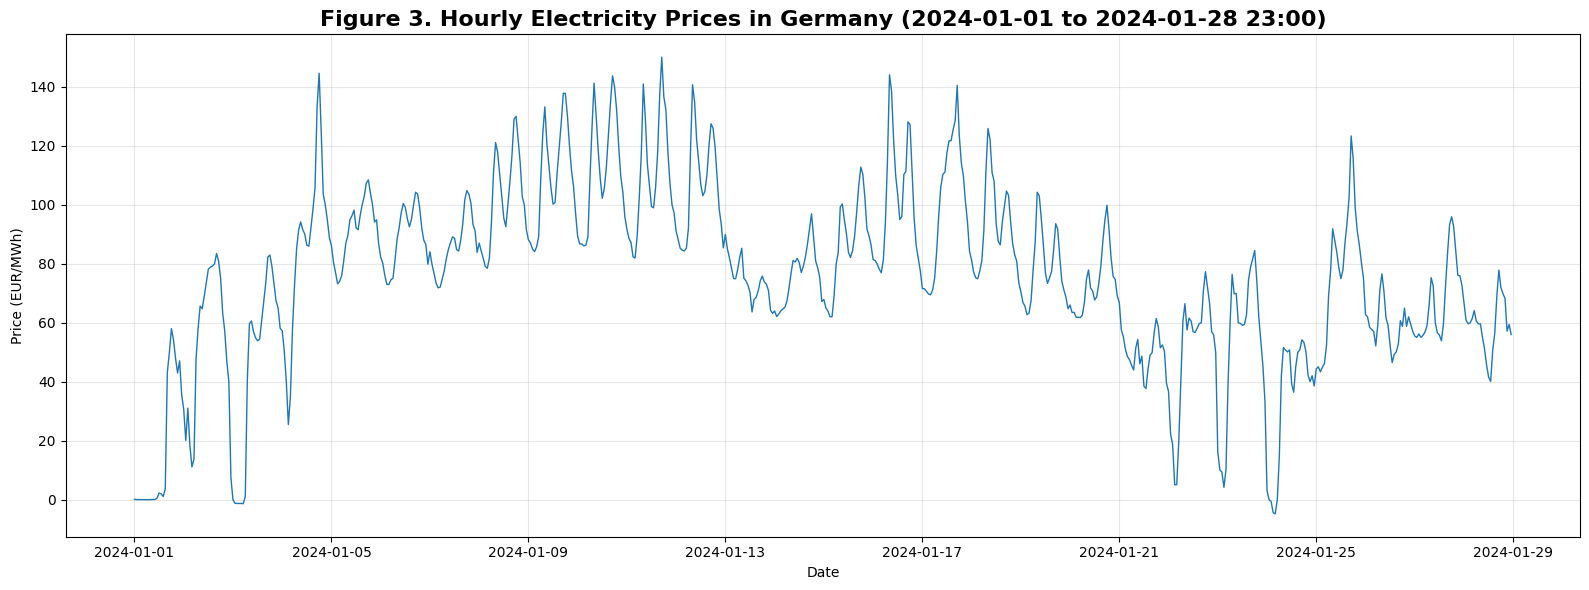

In [11]:
df = energy_prices_eu_frame.loc["2023-01-01":"2025-12-31"]

# ============================================================
# FIGURE 1 — Time series plot of all 20 channels
# Daily mean for readability
# ============================================================

fig, ax = plt.subplots(figsize=(18, 8))

daily_df = df.resample('D').mean()

for col in df.columns:
    ax.plot(
        daily_df.index,
        daily_df[col],
        linewidth=1.0,
        alpha=0.8,
        label=col
    )

ax.set_title(
    "Figure 1. Daily Mean Electricity Prices for 20 European Countries (2023–2025)",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Date")
ax.set_ylabel("Price (EUR/MWh)")
ax.grid(True, alpha=0.3)

# Place legend outside the plot area
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    frameon=False,
    fontsize=9
)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 2 — Correlation heatmap
# Justification for variate-attention models (e.g. iTransformer)
# ============================================================

corr = df.corr()

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot=False,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Figure 2. Cross-Country Correlation Matrix of Electricity Prices",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 3 — Single-country close-up (hourly resolution)
# Shows intra-day pattern (morning and evening peaks)
# ============================================================

country = "Germany"

# Select a 4-week window (example: January 2024)
start_date = "2024-01-01"
end_date = "2024-01-28 23:00"

closeup = df.loc[start_date:end_date, country]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    closeup.index,
    closeup.values,
    linewidth=1.0
)

ax.set_title(
    f"Figure 3. Hourly Electricity Prices in {country} "
    f"({start_date} to {end_date})",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Date")
ax.set_ylabel("Price (EUR/MWh)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# OPTIONAL: Save all figures to disk
# Uncomment if needed
# ============================================================

# fig1.savefig("figure1_all_channels_daily.png", dpi=300, bbox_inches="tight")
# fig2.savefig("figure2_correlation_heatmap.png", dpi=300, bbox_inches="tight")
# fig3.savefig("figure3_single_country_closeup.png", dpi=300, bbox_inches="tight")

In [12]:
from scipy.stats.mstats import winsorize

df_winsorized = df.apply(
    lambda col: pd.Series(
        winsorize(col.to_numpy(), limits=(0.005, 0.005)),
        index=col.index,
        name=col.name
    )
)

# Optional: verify the effect for one country
country = "Estonia"
print(f"Original max ({country}):   {df[country].max():.2f}")
print(f"Winsorized max ({country}): {df_winsorized[country].max():.2f}")

Original max (Estonia):   1896.00
Winsorized max (Estonia): 349.89


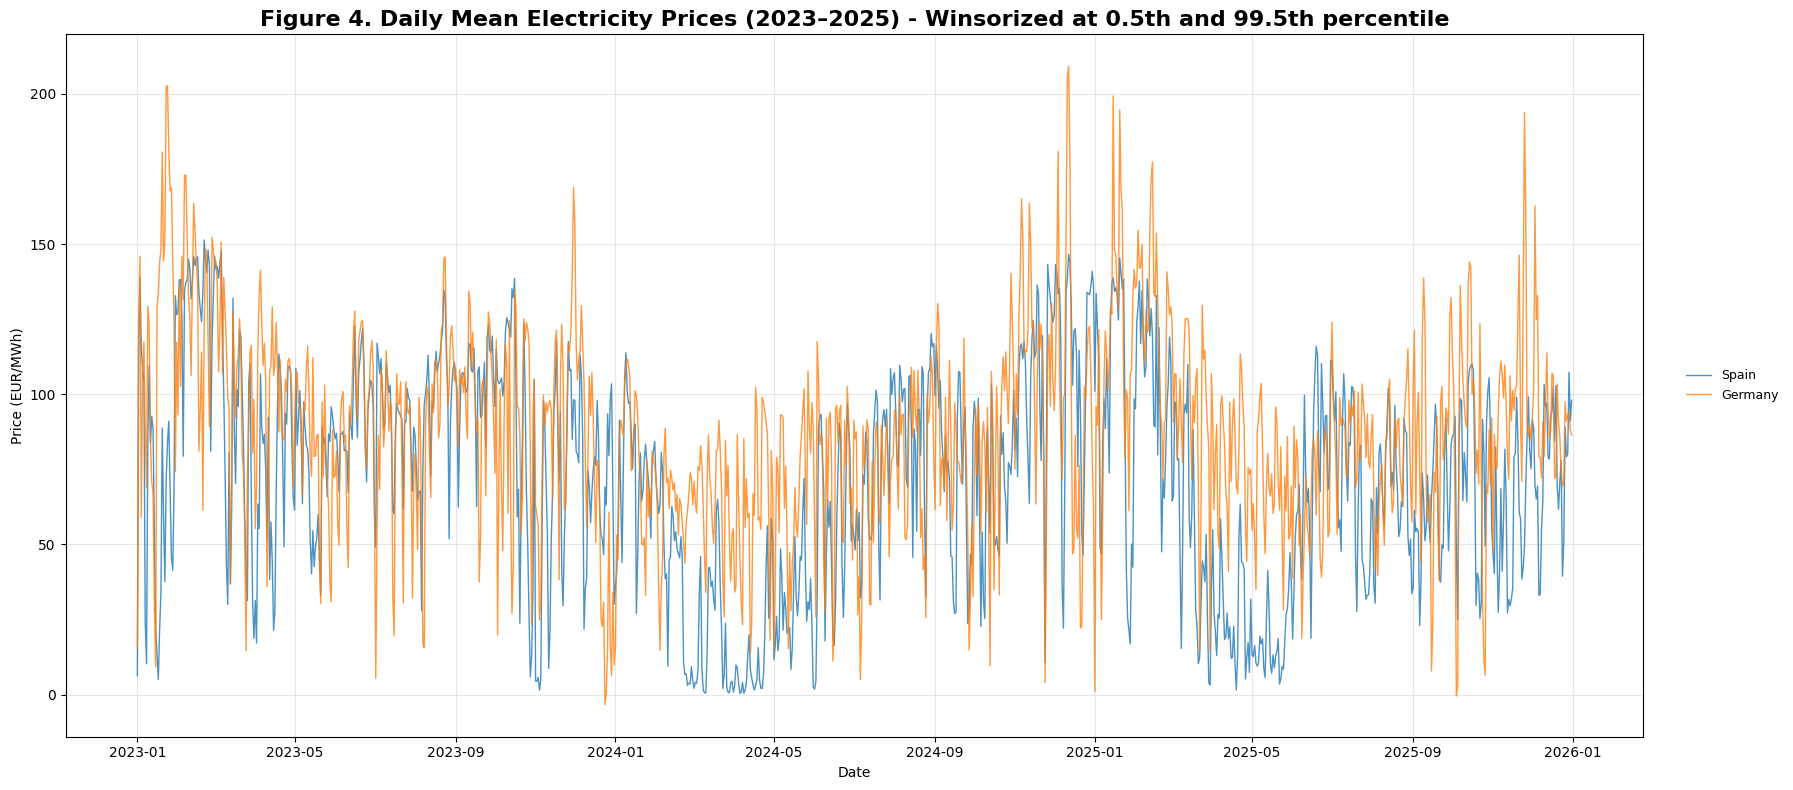

In [13]:
fig, ax = plt.subplots(figsize=(18, 8))

daily_df_winsorized = df_winsorized.resample('D').mean()

# for col in daily_df_winsorized.columns:
#     ax.plot(
#         daily_df_winsorized.index,
#         daily_df_winsorized[col],
#         linewidth=1.0,
#         alpha=0.8,
#         label=col
#     )

col = "Spain" 
ax.plot(
    daily_df_winsorized.index,
    daily_df_winsorized[col],
    linewidth=1.0,
    alpha=0.8,
    label=col
)

col = "Germany" 
ax.plot(
    daily_df_winsorized.index,
    daily_df_winsorized[col],
    linewidth=1.0,
    alpha=0.8,
    label=col
)
ax.set_title(
    "Figure 4. Daily Mean Electricity Prices (2023–2025) - Winsorized at 0.5th and 99.5th percentile",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Date")
ax.set_ylabel("Price (EUR/MWh)")
ax.grid(True, alpha=0.3)

# Place legend outside the plot area
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    frameon=False,
    fontsize=9
)

plt.tight_layout()
plt.show()

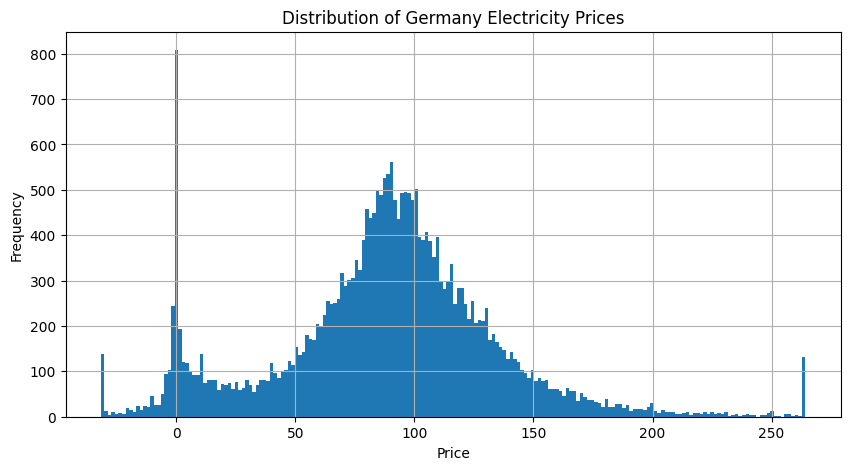

In [14]:

country = "Germany"

df_winsorized[country].hist(bins=200, figsize=(10,5))
plt.title(f"Distribution of {country} Electricity Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [15]:
from scipy.stats import kurtosis
avg_k = []
for country in df.columns:

    k = kurtosis(df[country], fisher=True)
    avg_k.append(k)

print("Excess kurtosis:", np.mean(avg_k))

Excess kurtosis: 23.914542458975355


In [ ]:
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from scipy.stats import norm, laplace
from scipy.optimize import minimize

           country  regime        mean        std    weight    kurtosis
0          Austria       0    1.479164   4.499343  0.042634   -0.150053
1          Austria       1   98.328877  45.423866  0.957366   18.686747
2          Belgium       0   14.786472  30.102145  0.113804   20.237466
3          Belgium       1   92.189645  40.730238  0.886196   10.188478
4         Bulgaria       0    4.666462   5.009630  0.042333   -1.413993
5         Bulgaria       1  108.843393  62.617572  0.957667   27.602825
6          Croatia       0    2.477404   4.109581  0.032160   -0.480415
7          Croatia       1  104.535141  53.350887  0.967840   21.608016
8   Czech_republic       0    2.257430   5.430675  0.043844   -0.268291
9   Czech_republic       1   98.454447  45.723431  0.956156   18.426859
10         Estonia       0    3.723166   3.612190  0.095822   -0.826063
11         Estonia       1   94.892560  68.409747  0.904178   98.351296
12         Finland       0   14.450580  14.427556  0.538047   -0

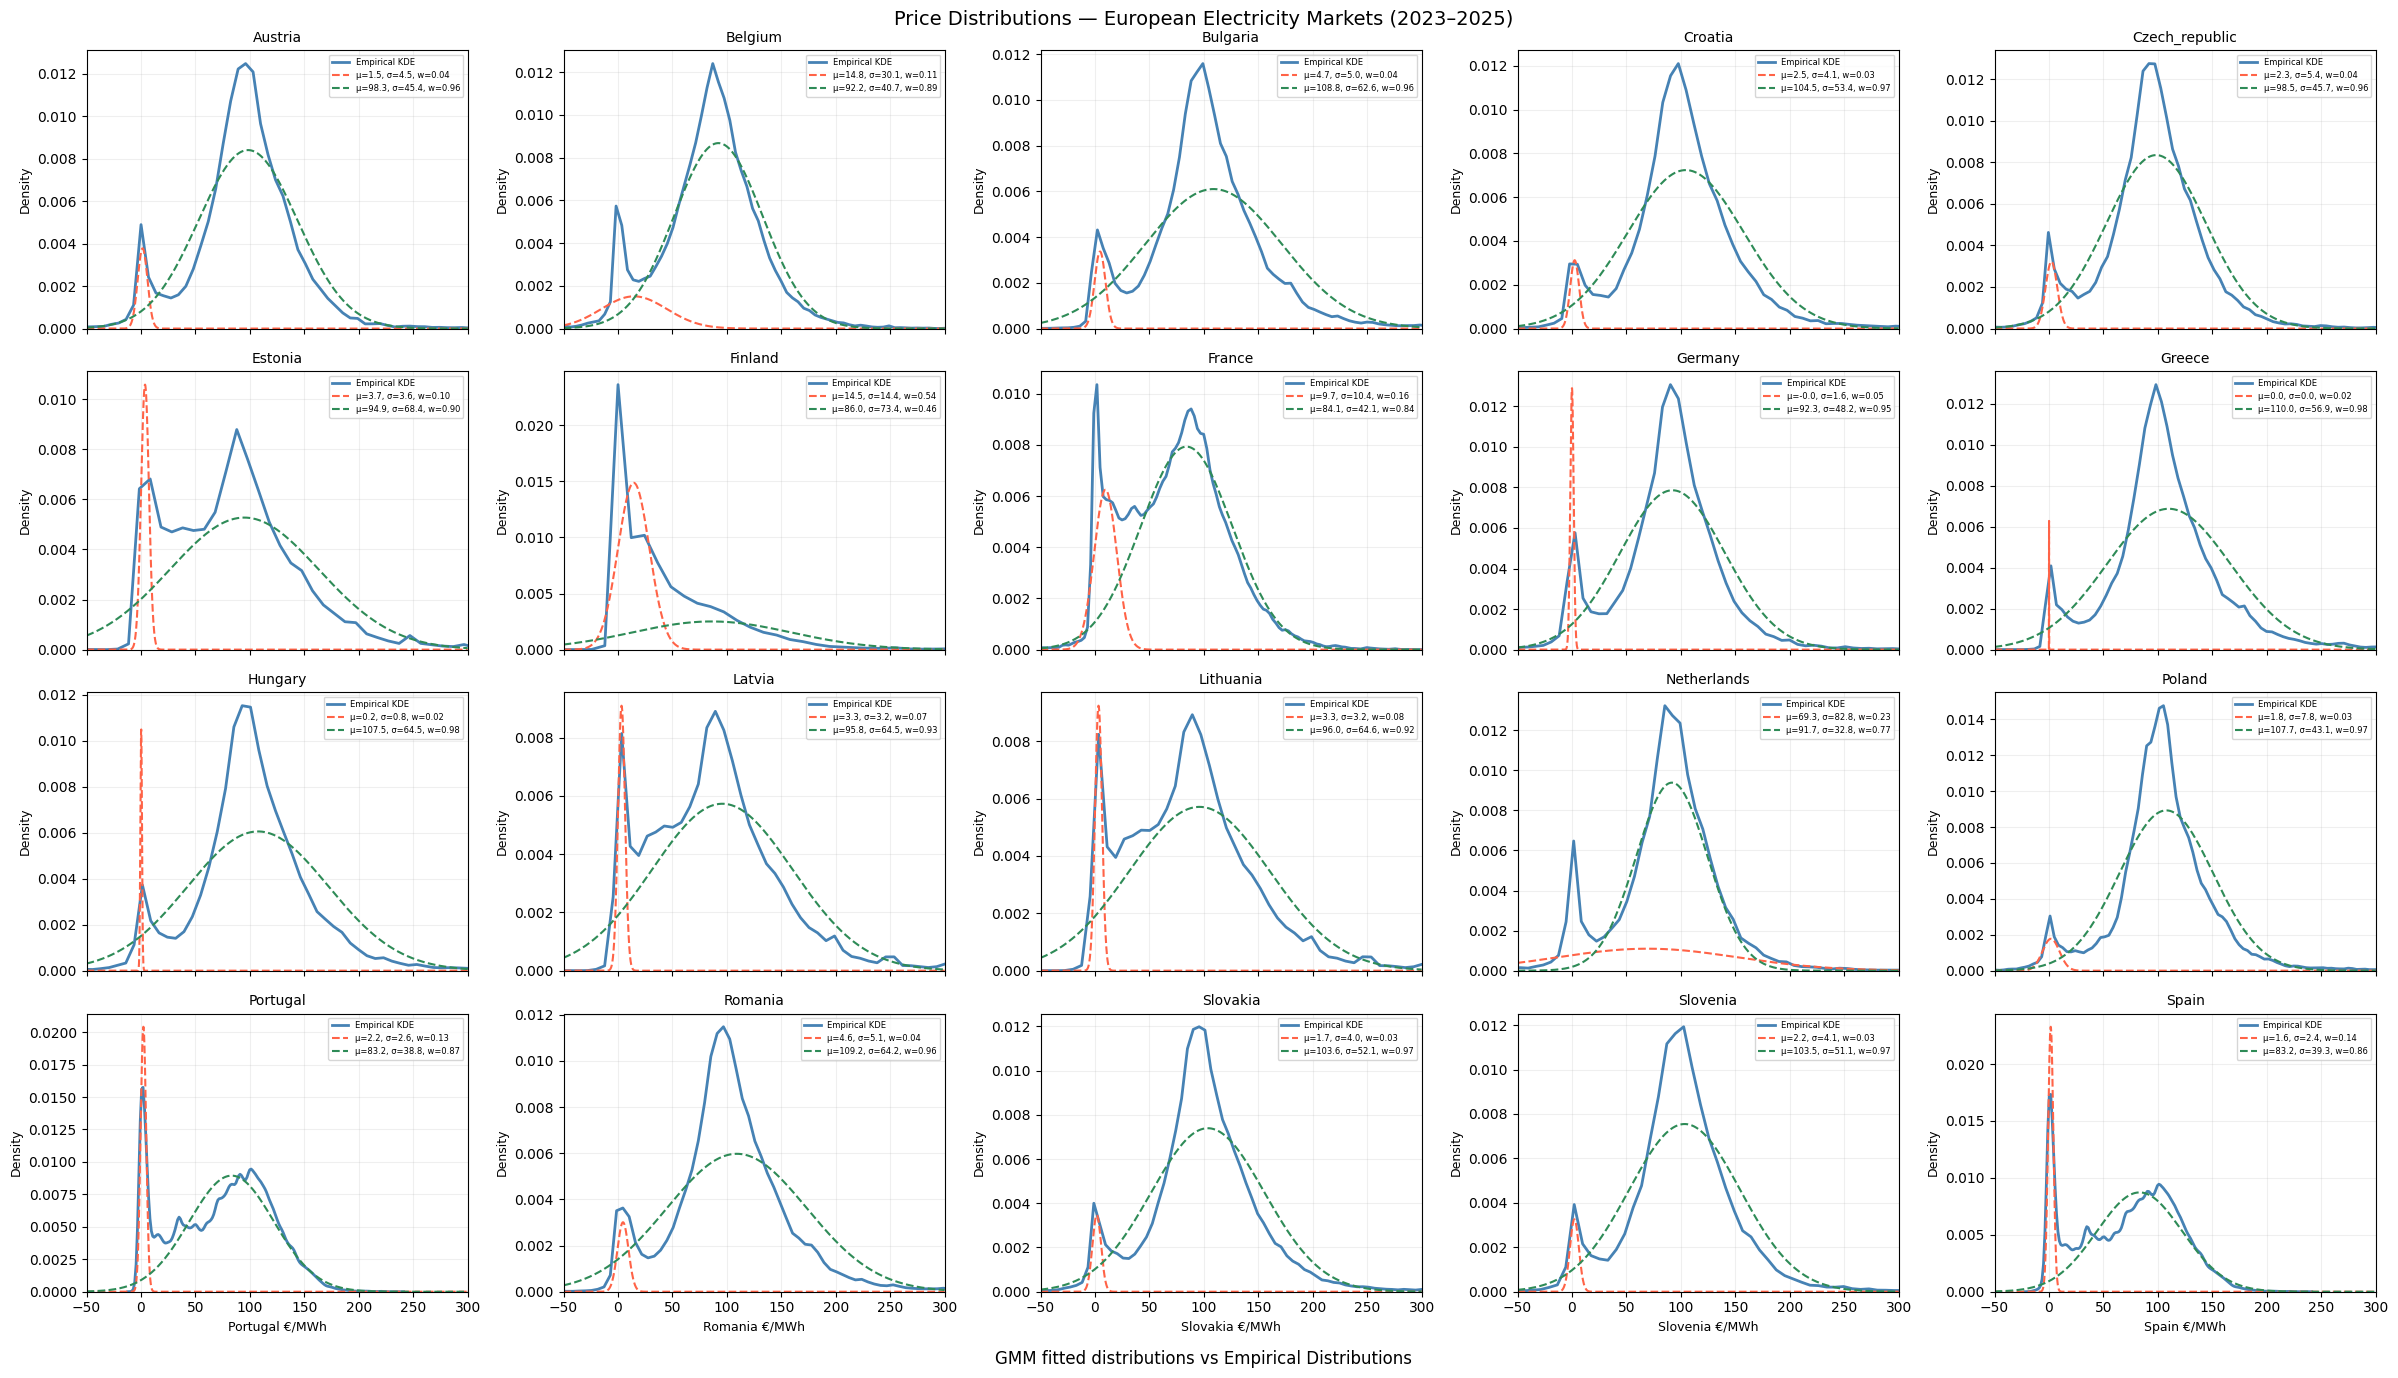

In [53]:
fig, axes = plt.subplots(4, 5, figsize=(24, 14), sharex=True)
axes = axes.flatten()

x_grid = np.linspace(-50, 300, 2000).reshape(-1, 1)
results = []
gmm_dict = {}

for i, country in enumerate(df.columns):
    ax = axes[i]
    ax.set_xlim(-50, 300)
    ax.set_title(f"{country}", fontsize=10)

    x = df[country].values
    x_2d = x.reshape(-1, 1)

    threshold = 20.0
    spike = x[x < threshold]
    heavy = x[x >= threshold]

    mu_spike, std_spike = spike.mean(), spike.std()
    mu_heavy, std_heavy = heavy.mean(), heavy.std()
    w_spike = len(spike) / len(x)
    w_heavy = len(heavy) / len(x)

    gmm = GaussianMixture(
        n_components=2,
        covariance_type='full',
        means_init=np.array([[mu_spike], [mu_heavy]]),
        precisions_init=np.array([
            [[1 / std_spike**2]],
            [[1 / std_heavy**2]]
        ]),
        max_iter=500,
        n_init=1,
        random_state=123
    )
    gmm.fit(x_2d)

    gmm_dict[country] = gmm

    means_fit  = gmm.means_
    covs_fit   = gmm.covariances_
    weights_fit = gmm.weights_

    # Empirical KDE — 1D input
    sns.kdeplot(x, bw_adjust=0.4, ax=ax, linewidth=2, color='steelblue', label="Empirical KDE")

    colors = ['tomato', 'seagreen']


    for regime in range(2):
        k = kurtosis(x_2d.flatten()[gmm.predict(x_2d) == regime], fisher=True)
        mu_val    = means_fit[regime].flatten()[0]
        sigma_val = np.sqrt(covs_fit[regime]).flatten()[0]
        w_val     = weights_fit[regime]

        # Weighted component
        component_pdf = w_val * norm.pdf(x_grid.flatten(), mu_val, sigma_val)

        ax.plot(
            x_grid, component_pdf,
            color=colors[regime], linestyle='--', linewidth=1.5,
            label=f"μ={mu_val:.1f}, σ={sigma_val:.1f}, w={w_val:.2f}"
        )

        results.append({
            "country": country,
            "regime": regime,
            "mean": mu_val,
            "std": sigma_val,
            "weight": w_val,
            "kurtosis": k
        })

    ax.set_xlabel(f"{country} €/MWh", fontsize=9)
    ax.set_ylabel("Density", fontsize=9)
    ax.legend(fontsize=6)
    ax.grid(alpha=0.2)

# Hide unused axes
for j in range(len(df.columns), len(axes)):
    axes[j].set_visible(False)

results_df = pd.DataFrame(results)
print(results_df)

fig.supxlabel("GMM fitted distributions vs Empirical Distributions", fontsize=12)
plt.suptitle("Price Distributions — European Electricity Markets (2023–2025)", fontsize=14)
plt.tight_layout()
plt.savefig("GMM_fit_KDE.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [54]:
heavy = results_df[results_df['regime'] == 1]
print(f"Average excess kurtosis (heavy regime): {heavy['kurtosis'].mean():.3f}")

Average excess kurtosis (heavy regime): 29.513


In [55]:
from scipy.stats import kurtosistest, normaltest, jarque_bera

for country in df.columns:
    x = df[country].dropna().values.reshape(-1, 1)
    
    # assign regimes using fitted GMM
    regimes = gmm_dict[country].predict(x)  # use your already-fitted GMMs
    heavy_data = x[regimes == 1].flatten()
    
    jb_stat, jb_p = jarque_bera(heavy_data)
    print(f"{country:20s} | JB stat: {jb_stat:10.1f} | p-value: {jb_p:.4f}")

Austria              | JB stat:   371313.7 | p-value: 0.0000
Belgium              | JB stat:   104829.8 | p-value: 0.0000
Bulgaria             | JB stat:   837432.0 | p-value: 0.0000
Croatia              | JB stat:   514715.9 | p-value: 0.0000
Czech_republic       | JB stat:   364107.2 | p-value: 0.0000
Estonia              | JB stat:  9519171.4 | p-value: 0.0000
Finland              | JB stat: 12858017.2 | p-value: 0.0000
France               | JB stat:     2574.7 | p-value: 0.0000
Germany              | JB stat:   506796.4 | p-value: 0.0000
Greece               | JB stat:   377839.6 | p-value: 0.0000
Hungary              | JB stat:   917754.3 | p-value: 0.0000
Latvia               | JB stat:  1393590.4 | p-value: 0.0000
Lithuania            | JB stat:  1365668.6 | p-value: 0.0000
Netherlands          | JB stat:       31.6 | p-value: 0.0000
Poland               | JB stat:    97584.0 | p-value: 0.0000
Portugal             | JB stat:      325.7 | p-value: 0.0000
Romania              | J

=== Suspiciously tight spikes (σ < 1) ===
             mean       std    weight
country                              
Greece   0.015635  0.020788  0.019425
Hungary  0.183505  0.757198  0.019997

=== High renewable signal (spike weight > 10%) ===
                  mean        std    weight
country                                    
Finland      14.450580  14.427556  0.538047
Netherlands  69.299387  82.771454  0.227558
France        9.660407  10.394636  0.162717
Spain         1.615632   2.400255  0.140050
Portugal      2.221592   2.556939  0.130854
Belgium      14.786472  30.102145  0.113804

=== Most volatile markets (heavy regime std) ===
                      mean        std
country                              
Finland          86.011775  73.386115
Estonia          94.892560  68.409747
Lithuania        95.991598  64.634823
Hungary         107.525443  64.535763
Latvia           95.842362  64.457595
Romania         109.160408  64.174521
Bulgaria        108.843393  62.617572
Greece    

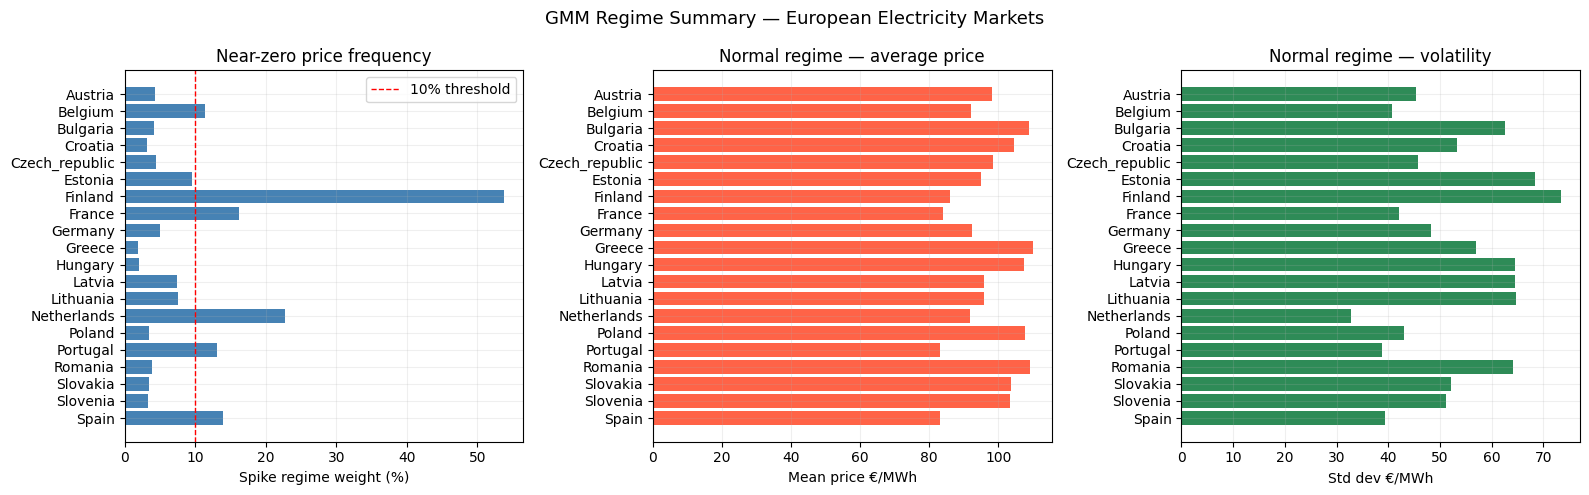

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

spike = results_df[results_df['regime'] == 0].set_index('country')
heavy = results_df[results_df['regime'] == 1].set_index('country')

# ── Flag anomalies ────────────────────────────────────────────
print("=== Suspiciously tight spikes (σ < 1) ===")
print(spike[spike['std'] < 1][['mean', 'std', 'weight']])

print("\n=== High renewable signal (spike weight > 10%) ===")
print(spike[spike['weight'] > 0.10][['mean', 'std', 'weight']].sort_values('weight', ascending=False))

print("\n=== Most volatile markets (heavy regime std) ===")
print(heavy[['mean', 'std']].sort_values('std', ascending=False))

# ── Cross-country comparison plot ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

countries = spike.index

# Spike weight (renewable signal)
axes[0].barh(countries, spike['weight'] * 100, color='steelblue')
axes[0].set_xlabel('Spike regime weight (%)')
axes[0].set_title('Near-zero price frequency')
axes[0].axvline(10, color='red', linestyle='--', linewidth=1, label='10% threshold')
axes[0].legend()

# Heavy regime mean (average price level)
axes[1].barh(countries, heavy['mean'], color='tomato')
axes[1].set_xlabel('Mean price €/MWh')
axes[1].set_title('Normal regime — average price')

# Heavy regime std (price volatility)
axes[2].barh(countries, heavy['std'], color='seagreen')
axes[2].set_xlabel('Std dev €/MWh')
axes[2].set_title('Normal regime — volatility')

for ax in axes:
    ax.grid(alpha=0.2)
    ax.invert_yaxis()

plt.suptitle('GMM Regime Summary — European Electricity Markets', fontsize=13)
plt.tight_layout()
plt.savefig('regime_summary.pdf', dpi=300, bbox_inches='tight')
plt.show()

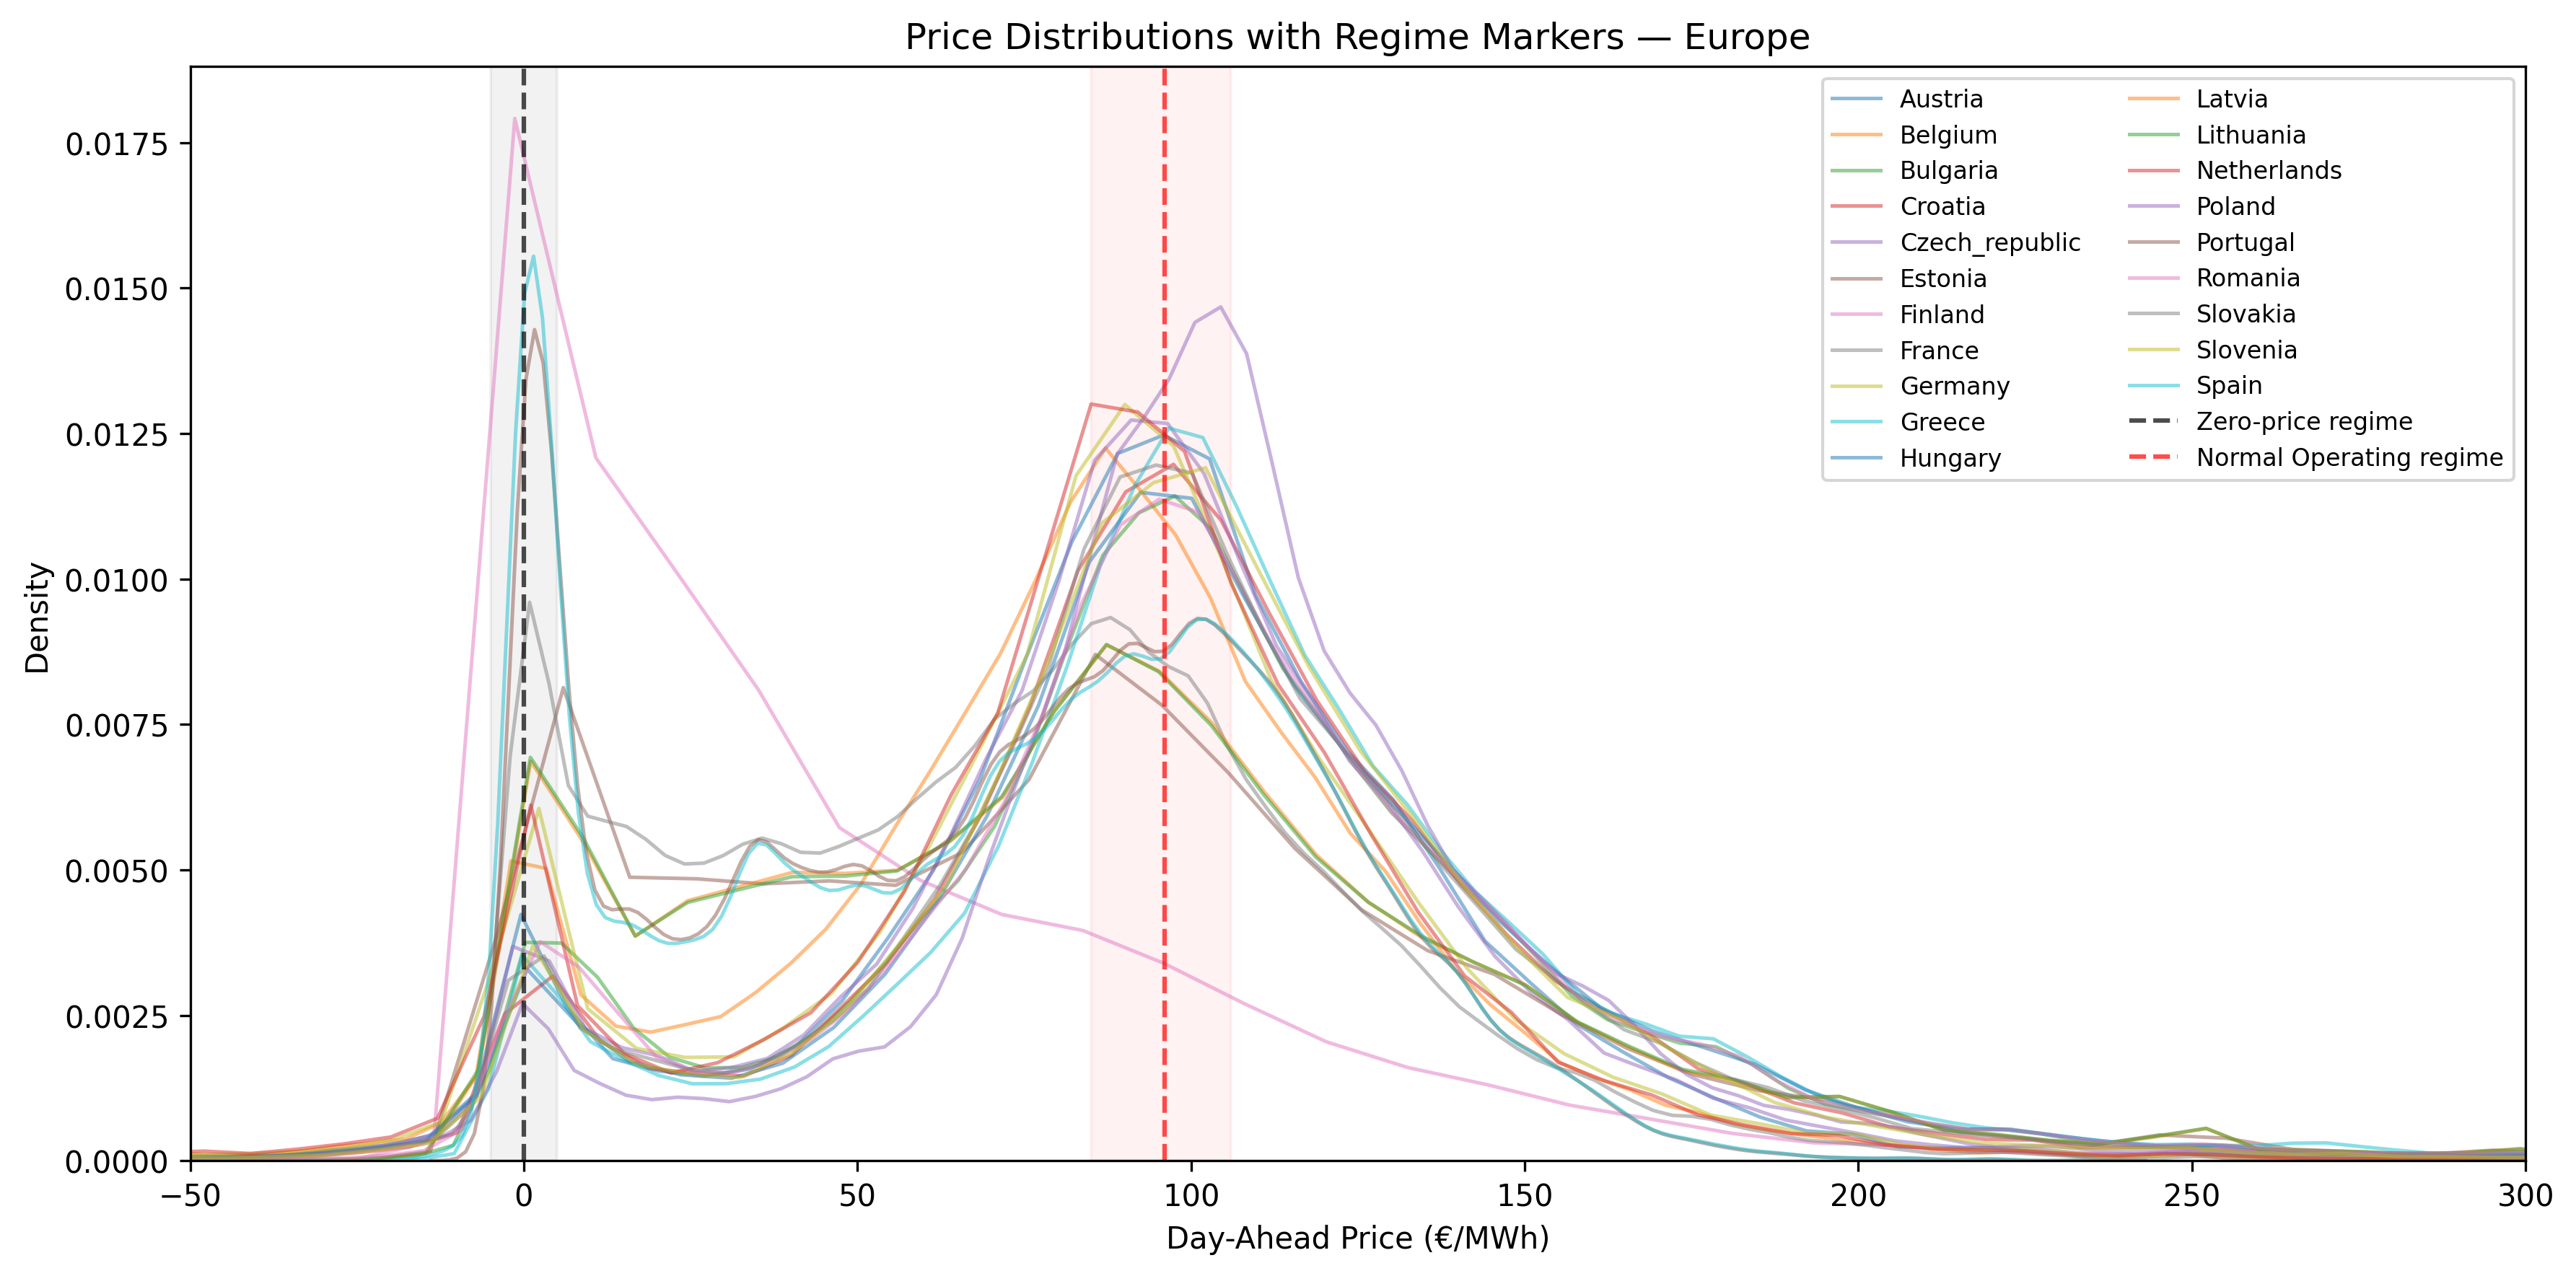

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for c in df.columns:
    sns.kdeplot(
        df[c],
        bw_adjust=0.5,
        ax=ax,
        linewidth=1.2,
        alpha=0.5,
        label=c
    )


# regime markers

ax.axvline(x=0, color='black', linestyle='--', alpha=0.7, label='Zero-price regime')
ax.axvline(x=96, color='red', linestyle='--', alpha=0.7, label='Normal Operating regime')

# highlight band around mean
ax.axvspan(85, 106, color='red', alpha=0.05)
ax.axvspan(-5, 5, color='black', alpha=0.05)

# formatting
ax.set_xlabel("Day-Ahead Price (€/MWh)")
ax.set_ylabel("Density")
ax.set_title("Price Distributions with Regime Markers — Europe")

ax.set_xlim(-50, 300)

ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig("price_distributions_with_regime_markers.pdf", dpi=300, bbox_inches="tight")
plt.show()

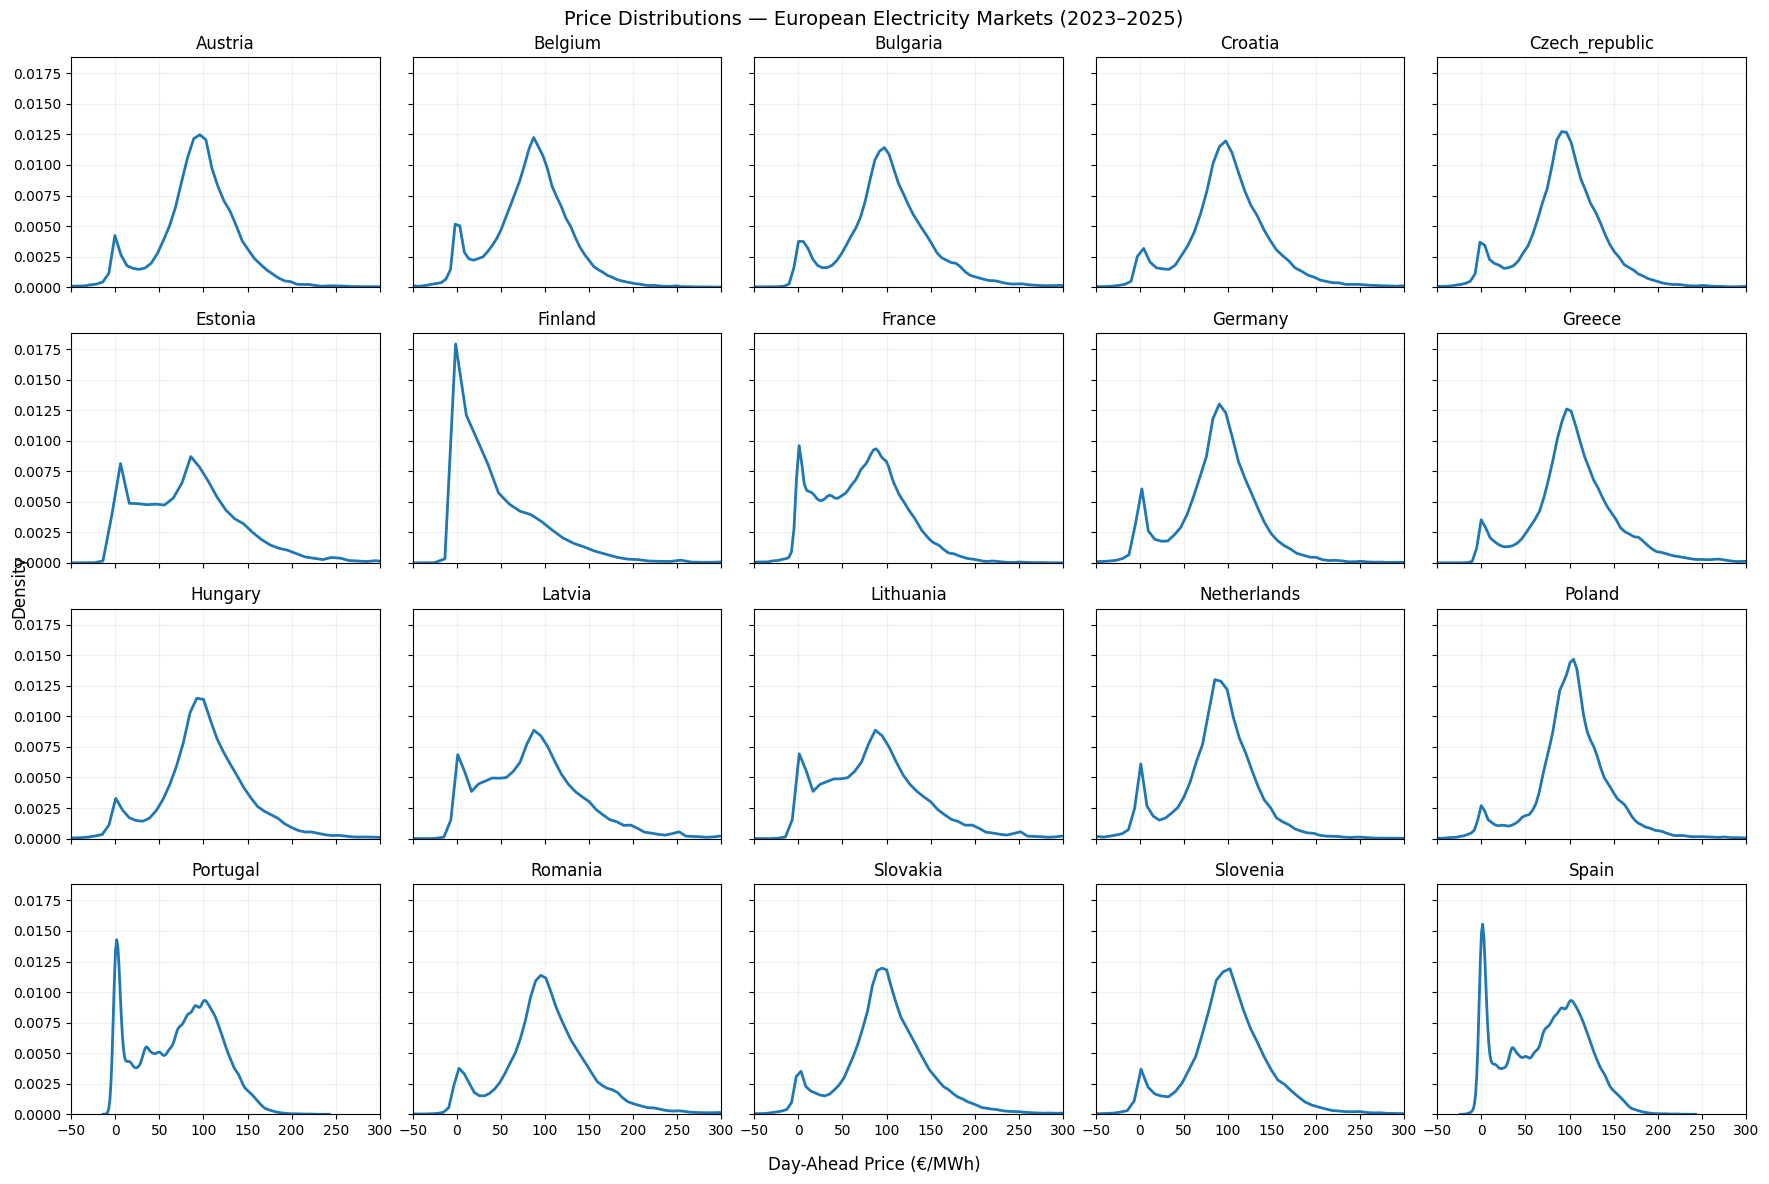

In [55]:

fig, axes = plt.subplots(4, 5, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, country in enumerate(df.columns):
    ax = axes[i]
    
    sns.kdeplot(
        df[country],
        bw_adjust=0.5,
        ax=ax,
        linewidth=2
    )
    
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(country, fontsize=12)
    ax.set_xlim(-50, 300)
    
    
    ax.grid(alpha=0.2)

# shared labels
fig.supylabel("Density", fontsize=12)
fig.supxlabel("Day-Ahead Price (€/MWh)", fontsize=12)

plt.suptitle("Price Distributions — European Electricity Markets (2023–2025)", fontsize=14)

plt.tight_layout()
plt.savefig("europe_price_distributions_panel.pdf", dpi=300, bbox_inches="tight")
plt.show()

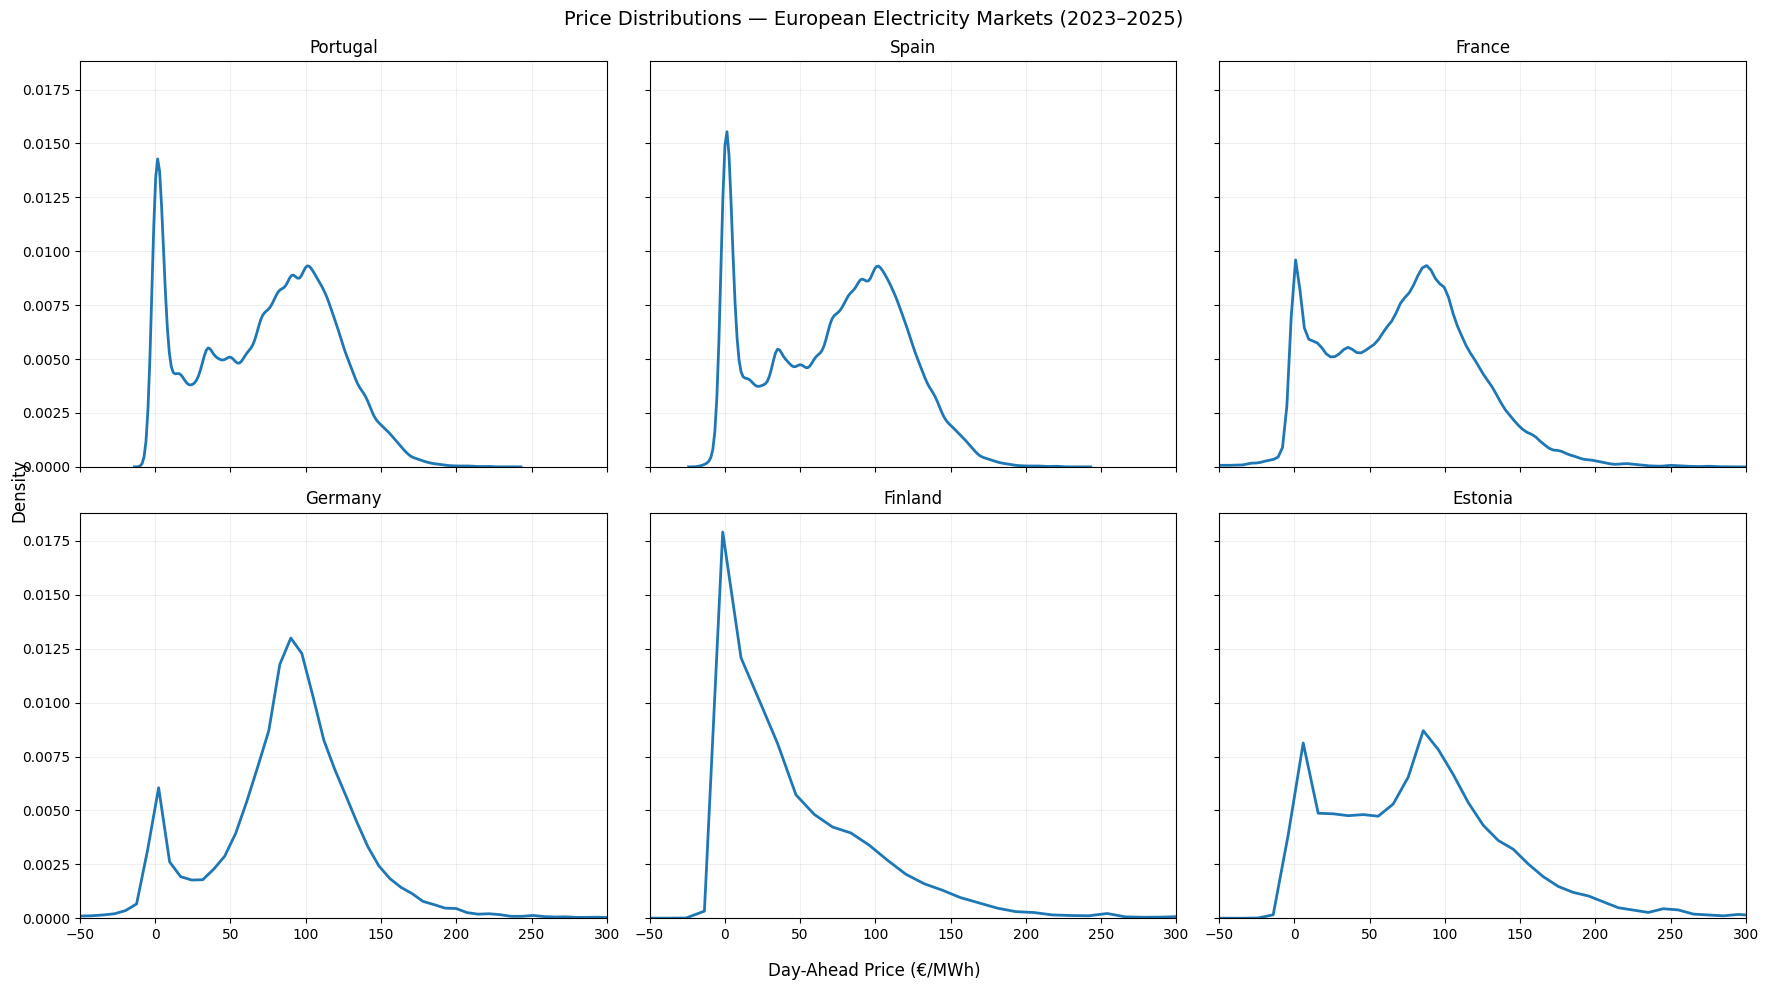

In [56]:
countries = ["Portugal", "Spain", "France", "Germany", "Finland", "Estonia"]


fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, country in enumerate(countries):
    ax = axes[i]
    
    sns.kdeplot(
        df[country],
        bw_adjust=0.5,
        ax=ax,
        linewidth=2
    )
    
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(country, fontsize=12)
    ax.set_xlim(-50, 300)
    
    
    ax.grid(alpha=0.2)

# shared labels
fig.supylabel("Density", fontsize=12)
fig.supxlabel("Day-Ahead Price (€/MWh)", fontsize=12)

plt.suptitle("Price Distributions — European Electricity Markets (2023–2025)", fontsize=14)

plt.tight_layout()
plt.savefig("europe_price_distributions_6panel.pdf", dpi=300, bbox_inches="tight")
plt.show()